# From Maxwell's equations to your patch-antenna FDTD code

This notebook rebuilds the idea behind your college project, one update at a time.
Run **Kernel → Restart Kernel and Run All Cells** in Jupyter. The included outputs
also let you read it without executing anything.

We will visualize a **3D Yee cell**, derive an update from a curl, simulate a small
**2D TMz wave with 3D surface plots**, and connect each step to `main.cu`.
The teaching simulation uses only NumPy and Matplotlib on the CPU; it is not the
full patch-antenna model. A 3D surface of Ez(x,y) is a plot of amplitude over a 2D
plane, not a three-dimensional electromagnetic simulation.

Install the notebook tools from the project root:

```bash
python3 -m pip install -r requirements-notebook.txt
python3 -m jupyterlab notebooks/FDTD_explained.ipynb
```

Use a virtual environment if your Python installation requires one. Choose its
kernel in Jupyter. Figures are static by default; rotating the view and rerunning
a cell needs no extra packages. For mouse rotation, optionally install `ipympl`
and run `%matplotlib widget` **before** the imports below (restart the kernel).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation
from pathlib import Path
import json

EPS0 = 8.8541878128e-12  # F/m
MU0 = 1.25663706212e-6   # H/m
C0 = 1 / np.sqrt(EPS0 * MU0)
plt.rcParams.update({'figure.figsize': (9, 6), 'font.size': 11})
print(f'Vacuum wave speed: {C0:.6g} m/s')


Vacuum wave speed: 2.99792e+08 m/s


## 1. What are we solving?

For a linear, isotropic, nondispersive material, D = εE and B = μH. Maxwell's
curl equations tell us how the fields change:

\[
\frac{\partial\mathbf E}{\partial t}
 = \frac{1}{\epsilon}(\nabla\times\mathbf H-\mathbf J),
\qquad
\frac{\partial\mathbf H}{\partial t}
 = -\frac{1}{\mu}\nabla\times\mathbf E.
\]

A **curl** measures local circulation. Differences in neighboring H samples
change E; differences in neighboring E samples change H. A uniform field has
zero curl and does not evolve in a uniform, source-free interior.

The other two Maxwell equations are constraints: ∇·D = ρ and ∇·B = 0. Compatible
initial conditions, sources obeying charge continuity, and a consistent Yee
update preserve the discrete constraints. Arbitrary field injection or material
handling does not automatically guarantee that.

Your pulse excites many frequencies at once. The metal and dielectric reshape
that pulse; Fourier analysis of the recorded signals reveals frequency response.


## 2. Put field components at different places: the Yee cell

E components sit along cell edges; H components sit at face centers on a dual
grid. The arrow direction represents the component's axis, **not a field value**.
Coordinates below are normalized to one cell; the real cell has unequal Δx, Δy,
and Δz. Shared samples belong to neighboring cells too.


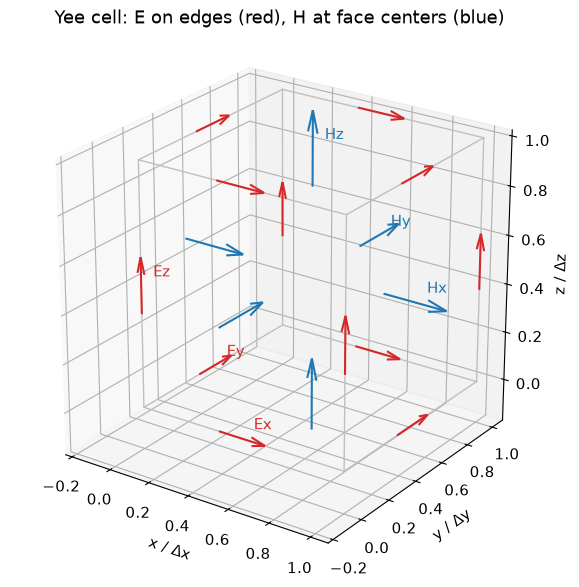

In [2]:
from itertools import product
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
for start in product((0, 1), repeat=3):
    for axis in range(3):
        if start[axis] == 0:
            end = list(start); end[axis] = 1
            ax.plot(*zip(start, end), color='0.75', linewidth=1)
# Every edge midpoint for E, both face centers for each H component.
for axis, name in enumerate(('x', 'y', 'z')):
    for other in product((0, 1), repeat=2):
        point = np.zeros(3); point[axis] = .5
        point[[a for a in range(3) if a != axis]] = other
        direction = np.eye(3)[axis] * .23
        ax.quiver(*(point-direction/2), *direction, color='tab:red', arrow_length_ratio=.3)
    for side in (0, 1):
        point = np.full(3, .5); point[axis] = side
        direction = np.eye(3)[axis] * .30
        ax.quiver(*(point-direction/2), *direction, color='tab:blue', arrow_length_ratio=.3)
    e = np.zeros(3); e[axis] = .5
    h = np.full(3, .5); h[axis] = 1
    ax.text(*(e+.035), f'E{name}', color='tab:red')
    ax.text(*(h+.035), f'H{name}', color='tab:blue')
ax.set(xlabel='x / Δx', ylabel='y / Δy', zlabel='z / Δz',
       title='Yee cell: E on edges (red), H at face centers (blue)')
ax.set_box_aspect((1, 1, 1)); ax.view_init(elev=24, azim=-55)
plt.show()


## 3. Replace derivatives with nearby differences

Consider the z component of Ampère's law without current:

\[
\frac{\partial E_z}{\partial t}
=\frac{1}{\epsilon}
\left(\frac{\partial H_y}{\partial x}-\frac{\partial H_x}{\partial y}\right).
\]

Around Ez(i,j,k+½), use Hy at x = i±½ and Hx at y = j±½. Both spatial
differences are centered on that Ez location:

\[
E_z^{n+1}(i,j,k+\tfrac12)=E_z^n(i,j,k+\tfrac12)
+\frac{\Delta t}{\epsilon}\left[
\frac{H_y^{n+1/2}(i+\tfrac12,j,k+\tfrac12)-H_y^{n+1/2}(i-\tfrac12,j,k+\tfrac12)}{\Delta x}
-\frac{H_x^{n+1/2}(i,j+\tfrac12,k+\tfrac12)-H_x^{n+1/2}(i,j-\tfrac12,k+\tfrac12)}{\Delta y}
\right].
\]

Your `UpdateEz` implements this stencil using array indices instead of half-index
coordinates:

```cpp
Ez[i][j][k] += tEPX * (Hy[i][j][k] - Hy[i-1][j][k])
             - tEPY * (Hx[i][j][k] - Hx[i][j-1][k]);
```

`tEPX = Δt/(ε0 Δx)` and `tEPY = Δt/(ε0 Δy)` in free space. Different
coefficients account for dielectric and interface regions. The diagram uses a
coordinate convention for physical sample locations; array index zero need not
mean the same physical origin for every component.


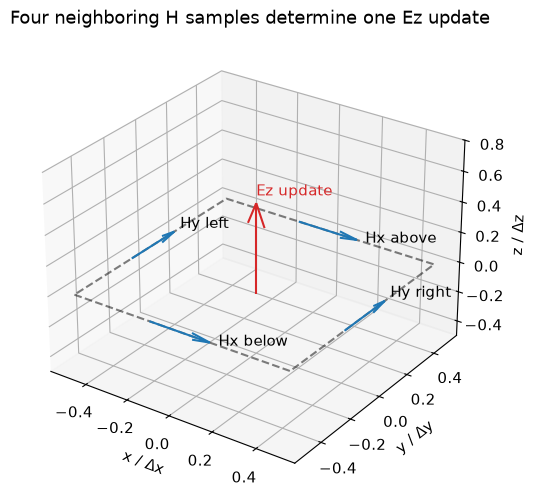

In [3]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
for x, label in [(-.5, 'Hy left'), (.5, 'Hy right')]:
    ax.quiver(x, -.14, 0, 0, .28, 0, color='tab:blue', arrow_length_ratio=.3)
    ax.text(x, .18, 0, label)
for y, label in [(-.5, 'Hx below'), (.5, 'Hx above')]:
    ax.quiver(-.14, y, 0, .28, 0, 0, color='tab:blue', arrow_length_ratio=.3)
    ax.text(.18, y, 0, label)
ax.quiver(0, 0, -.1, 0, 0, .6, color='tab:red', arrow_length_ratio=.25)
ax.text(0, 0, .55, 'Ez update', color='tab:red')
ax.plot([-.5,.5,.5,-.5,-.5],[-.5,-.5,.5,.5,-.5], np.zeros(5), 'k--', alpha=.5)
ax.set(xlabel='x / Δx', ylabel='y / Δy', zlabel='z / Δz',
       title='Four neighboring H samples determine one Ez update')
ax.set_zlim(-.5,.8); ax.view_init(elev=28, azim=-55)
plt.show()


## 4. Stagger time too: the leapfrog update

E lives at integer times and H at half times. Start with Eⁿ and Hⁿ⁻½:

1. Compute Hⁿ⁺½ from the curl of Eⁿ.
2. Compute Eⁿ⁺¹ from the curl of Hⁿ⁺½.
3. Apply the specified source and boundary conditions at their appropriate stages.

Neither update needs a global linear-system solve. In a uniform lossless interior,
the centered method is second-order accurate in space and time. Material jumps,
sources, and boundary approximations can limit overall accuracy.

Your program starts its loop with the E update, then the H update. That is the
same leapfrog arrangement with a different starting time label, not two fields
being updated at the same physical time.


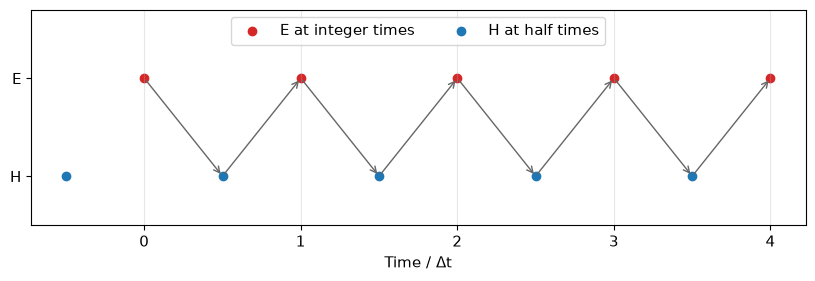

In [4]:
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.scatter(np.arange(5), np.ones(5), c='tab:red', label='E at integer times')
ax.scatter(np.arange(5)-.5, np.zeros(5), c='tab:blue', label='H at half times')
for n in range(4):
    ax.annotate('', (n+.5, 0), (n, 1), arrowprops={'arrowstyle':'->', 'color':'0.4'})
    ax.annotate('', (n+1, 1), (n+.5, 0), arrowprops={'arrowstyle':'->', 'color':'0.4'})
ax.set(xlabel='Time / Δt', yticks=[0,1], yticklabels=['H','E'], ylim=(-.5,1.7))
ax.legend(loc='upper center', ncol=2); ax.grid(axis='x', alpha=.3)
plt.show()


## 5. Choose a stable time step

For the Cartesian Yee scheme in an isotropic medium, the three-dimensional
Courant bound is

\[
\Delta t \leq \frac{1}{v_{\max}
\sqrt{\Delta x^{-2}+\Delta y^{-2}+\Delta z^{-2}}}.
\]

Use the **fastest** wave speed anywhere in the domain. Your air region is faster
than the εr=2.2 substrate, so use the vacuum speed. Stability does not guarantee
accuracy: waves also need enough cells per wavelength, with convergence checked
by refining the mesh. The bound here is for the interior scheme; boundary and
material algorithms must also be stable.


In [5]:
patch_spacing = np.array([.389e-3, .400e-3, .265e-3])
patch_dt = .441e-12
limit = 1 / (C0 * np.sqrt(np.sum(patch_spacing**-2)))
print(f'Patch Δt: {patch_dt*1e12:.3f} ps')
print(f'3D interior Courant limit: {limit*1e12:.3f} ps')
print(f'Fraction of limit: {patch_dt/limit:.3f}')
assert patch_dt < limit


Patch Δt: 0.441 ps
3D interior Courant limit: 0.641 ps
Fraction of limit: 0.688


## 6. A small working example: 2D TMz

To see propagation clearly, remove z variation (∂/∂z = 0) and retain Ez, Hx, Hy:

\[
\partial_t H_x=-\frac{1}{\mu}\partial_y E_z,\quad
\partial_t H_y=+\frac{1}{\mu}\partial_x E_z,\quad
\partial_t E_z=\frac{1}{\epsilon}(\partial_x H_y-\partial_y H_x).
\]

We use a vacuum square cavity with **PEC walls**, where Ez=0 at the outer edges.
A smooth Gaussian initial Ez distribution launches waves; H starts at zero.
This is an initial-value problem, not the driven patch antenna. Here ∇·D=0
because Ez is independent of z, and the in-plane initial H is zero.

The arrays have deliberately different shapes: Ez(nx,ny), Hx(nx,ny−1),
Hy(nx−1,ny). Those shapes make staggering visible. No `np.roll` is used, so the
opposite walls are not accidentally connected by periodic indexing.


In [6]:
# Change these and rerun this cell and the cells below.
nx = ny = 81
dx = dy = 1e-3
courant_fraction = 0.95  # must be <= 1 for the 2D interior bound
steps = 180
save_every = 6
assert 0 < courant_fraction <= 1
assert nx >= 5 and ny >= 5 and steps > 0 and save_every > 0

dt = courant_fraction / (C0 * np.sqrt(dx**-2 + dy**-2))
x = np.arange(nx) * dx
y = np.arange(ny) * dy
X, Y = np.meshgrid(x, y, indexing='ij')
ez = np.exp(-((X-x.mean())**2 + (Y-y.mean())**2)/(5*dx)**2)
ez[[0,-1],:] = 0
ez[:,[0,-1]] = 0
hx = np.zeros((nx, ny-1))
hy = np.zeros((nx-1, ny))
snapshots = [ez.copy()]
snapshot_steps = [0]
peak = [np.max(np.abs(ez))]

for n in range(steps):
    # E^n -> H^(n+1/2); both right-hand sides use the same E.
    hx -= dt / (MU0 * dy) * (ez[:,1:] - ez[:,:-1])
    hy += dt / (MU0 * dx) * (ez[1:,:] - ez[:-1,:])
    # H^(n+1/2) -> E^(n+1), only interior Ez samples.
    curl_h = ((hy[1:,1:-1] - hy[:-1,1:-1]) / dx
              - (hx[1:-1,1:] - hx[1:-1,:-1]) / dy)
    ez[1:-1,1:-1] += dt / EPS0 * curl_h
    # PEC boundary samples stay zero because we never update them.
    peak.append(np.max(np.abs(ez)))
    if (n+1) % save_every == 0:
        snapshots.append(ez.copy())
        snapshot_steps.append(n+1)

snapshots = np.array(snapshots)
assert np.isfinite(snapshots).all()
assert np.max(np.abs(snapshots)) < 5  # gross instability smoke check, not proof
assert np.all(snapshots[:,[0,-1],:] == 0)
assert np.all(snapshots[:,:,[0,-1]] == 0)
print(f'Δt = {dt*1e12:.3f} ps; {len(snapshots)} saved frames')
print(f'Ez: {ez.shape}, Hx: {hx.shape}, Hy: {hy.shape}')


Δt = 2.241 ps; 31 saved frames
Ez: (81, 81), Hx: (81, 80), Hy: (80, 81)


## 7. Watch the pulse spread and reflect in 3D plots

The horizontal axes are position; the vertical axis is **Ez amplitude**, not
physical height. Negative lobes are meaningful field polarity. The fixed color
scale makes amplitudes comparable. The pulse reaches the PEC walls and reflects;
this example deliberately has no absorbing boundary.


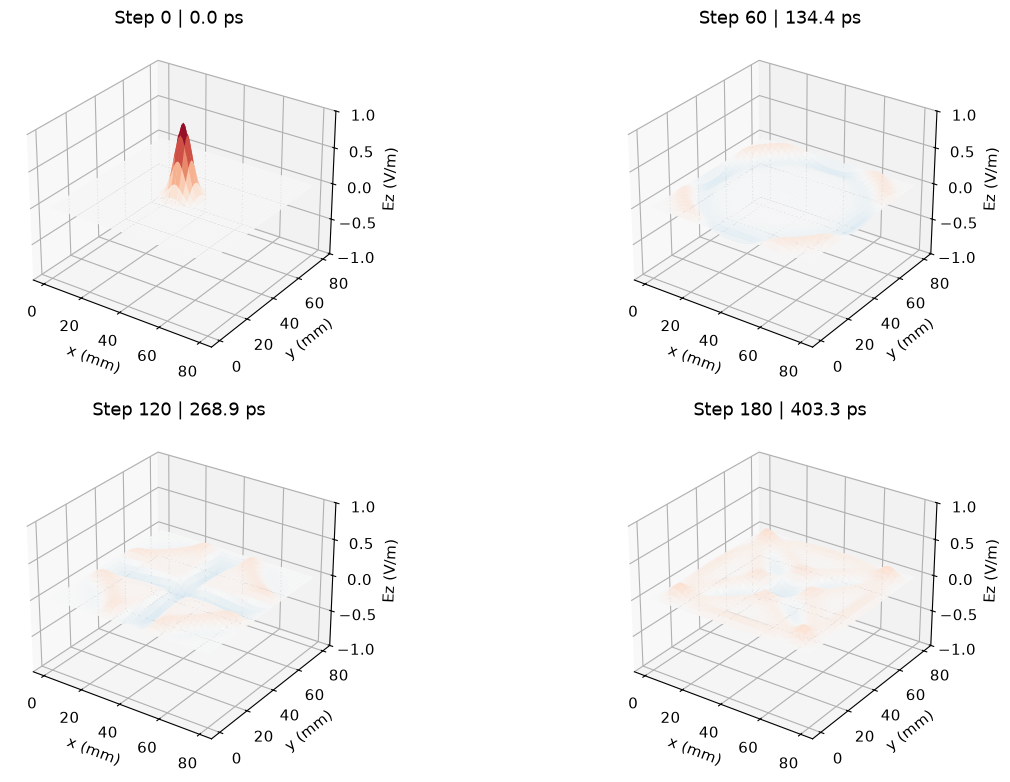

In [7]:
fig = plt.figure(figsize=(14, 8))
for panel, index in enumerate(np.linspace(0, len(snapshots)-1, 4, dtype=int), 1):
    ax = fig.add_subplot(2, 2, panel, projection='3d')
    ax.plot_surface(X*1e3, Y*1e3, snapshots[index], cmap='RdBu_r',
                    vmin=-1, vmax=1, rstride=2, cstride=2, linewidth=0)
    ax.set(xlabel='x (mm)', ylabel='y (mm)', zlabel='Ez (V/m)', zlim=(-1,1),
           title=f'Step {snapshot_steps[index]} | {snapshot_steps[index]*dt*1e12:.1f} ps')
    ax.view_init(elev=28, azim=-55)
fig.tight_layout()
plt.show()


The animation below is embedded as JavaScript inside the notebook. It needs
neither FFmpeg nor a GPU. Matplotlib renders a small number of frames so the
notebook stays manageable.


In [8]:
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111, projection='3d')
ax.set(xlabel='x (mm)', ylabel='y (mm)', zlabel='Ez (V/m)', zlim=(-1,1))
ax.view_init(elev=28, azim=-55)
surface = [None]
def draw_frame(index):
    if surface[0] is not None:
        surface[0].remove()
    surface[0] = ax.plot_surface(X*1e3, Y*1e3, snapshots[index], cmap='RdBu_r',
                                 vmin=-1, vmax=1, rstride=3, cstride=3)
    ax.set_title(f'Step {snapshot_steps[index]} | t = {snapshot_steps[index]*dt*1e12:.1f} ps')
    return (surface[0],)

animation = FuncAnimation(fig, draw_frame, frames=len(snapshots), interval=100, blit=False)
html = animation.to_jshtml()
plt.close(fig)
display(HTML(html))


## 8. How this becomes a patch antenna

Your solver keeps all six field components and all three spatial derivatives.
The εr=2.2 substrate changes E-update coefficients. For a perfect conductor,
tangential E is zero at the copper surface; the source drives the feed, and
absorbing outer boundaries approximate an open domain.

| Idea | Your CUDA implementation |
|---|---|
| Δx, Δy, Δz, Δt; coefficients | `InitializeData` |
| Advance E using curl H | `UpdateEx`, `UpdateEy`, `UpdateEz` |
| Ground, microstrip, patch PEC conditions | `Conductors`, `GroundPlane`, `uStrip`, `PatchAntenna` |
| Gaussian feed excitation | `Source`, `GaussianSource` |
| Advance H using −curl E | `UpdateHx`, `UpdateHy`, `UpdateHz` |
| Approximate open-domain boundary | `FirstABC`, `SecondABC` |
| Compare antenna against strip reference | `STRIP` build and `plotEz.py` |
| Save Ez slice for visualization | `FieldOutput` in `output.h` |

CUDA distributes cell updates over many threads. The numerical method still
requires the same curls, staggering, and stability bound. A fast GPU does not
permit a larger physical time step.

The first-order absorbing boundaries in this project can reflect some energy.
Our PEC teaching example reflects intentionally and must not be interpreted as
a radiation or S11 calculation. Likewise, the project's existing reflection
plot retains its original source normalization rather than a calibrated port
measurement.


## 9. Optional: inspect an actual antenna run

This cell uses an existing complete run if available. It does not compile or
launch the CUDA program. Run `python3 simulate.py --output runs/1` from the
project root first, or change `run_dir` below.


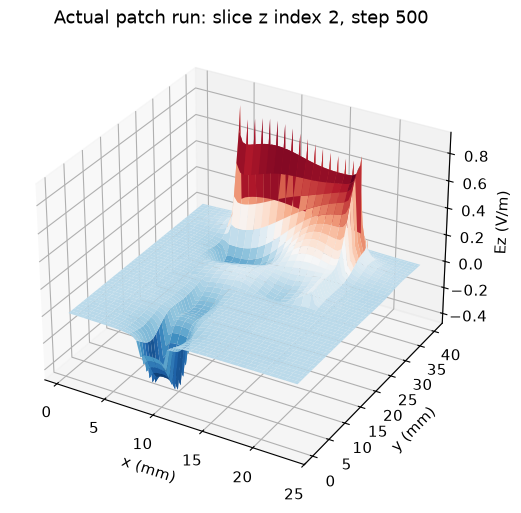

In [9]:
# Locate the repository whether Jupyter starts in the root or notebooks/.
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'main.cu').is_file()), None)
run_dir = root/'runs'/'1' if root else Path('runs/1')
if not (run_dir/'metadata.json').exists():
    print(f'Optional run not found: {run_dir}. The teaching example above is complete.')
else:
    meta = json.loads((run_dir/'metadata.json').read_text())
    if meta.get('status') != 'complete':
        print('Run is incomplete; wait for the simulation to finish.')
    else:
        actual = np.load(run_dir/'antenna'/'fields.npy', mmap_mode='r')
        frame_index = min(100, len(actual)-1)
        xx, yy = np.meshgrid((np.arange(actual.shape[1])+1)*meta['dx']*1e3,
                             (np.arange(actual.shape[2])+1)*meta['dy']*1e3, indexing='ij')
        fig = plt.figure()
        ax = fig.add_subplot(111, projection='3d')
        ax.plot_surface(xx, yy, actual[frame_index], cmap='RdBu_r')
        step = frame_index*meta['sample_every']
        ax.set(xlabel='x (mm)', ylabel='y (mm)', zlabel='Ez (V/m)',
               title=f'Actual patch run: slice z index {meta["slice_z"]}, step {step}')
        plt.show()


## 10. Experiments to try

- Change `courant_fraction` from 0.95 to 0.5. The same number of steps covers less
  physical time; compare plots at the same time before judging propagation speed.
- Change the grid spacing and Gaussian width together to keep the same physical
  problem. Refine both space and time to study numerical dispersion.
- Change `azim` in `view_init` to inspect a surface from another direction.
- To investigate instability, work in a copy and remove the upper-bound assertion
  before trying a Courant fraction above one. The numerical growth is an artifact,
  not an amplified physical wave.
- Add a dielectric region only after introducing spatially varying ε in the E
  update; a cavity mode in uniform vacuum does not model a patch antenna.

### Further reading

- John B. Schneider, [Understanding the FDTD Method](https://eecs.wsu.edu/~schneidj/ufdtd/index.html),
  especially the Yee algorithm, numerical dispersion, and multidimensional FDTD chapters.
- Schneider's [multidimensional derivation and code](https://github.com/john-b-schneider/uFDTD/blob/master/fdtd-multidimensional.tex).
- University of Arizona, [UAFDTD manual, Appendix B](https://wp.optics.arizona.edu/milster/wp-content/uploads/sites/48/2016/06/uafdtd-GUI-manual-111906b.pdf),
  for Yee-cell placement and the Courant criterion.

The explanations and teaching code here are written for this repository; they
are not copied from the reference implementations.
